**Generative AI Use**: For the purposes of the assignments, the use of generative AI is subject to the same policies regarding collaboration. Just as with other collaborators, each student must write down the solutions independently of the output of the interaction and the submission should include a note denoting the nature of the collaboration. The use of generative AI tools to substantially complete sections of the assignments is not in line with the spirit of the assignments, and would be a violation of the [Honor Code](https://communitystandards.stanford.edu/policies-and-guidance/honor-code).

---

**中文对照（参考译文，不含解答）**

**生成式 AI 的使用**：本作业对生成式 AI 的使用采用与协作相同的规则。与其他协作者交流之后，每位学生仍须独立写出自己的解答，不能直接依赖交流中得到的输出；提交时应附上说明，如实记录协作的性质。使用生成式 AI 实质性地完成作业的大部分内容，不符合本作业的教学目的，也会违反[学术诚信准则](https://communitystandards.stanford.edu/policies-and-guidance/honor-code)。

**Student Declaration (must be completed)**

**SUNet id:**  
_Your SUNet id_

**Did you use generative AI tools (e.g., ChatGPT, Copilot, etc.)?**  
- [ ] No  
- [ ] Yes (please describe below)

**If yes, describe how you used generative AI and for what parts of the assignment :**  
_Your Answer_

**Confirm that all submitted work reflects your own understanding and that you did not rely on AI to complete substantial portions of the assignment:**  
- [ ] I confirm

---

**中文对照（参考译文，不含解答）**

**学生声明（必须填写）**

**SUNet 账号：** [请自行填写]

**你是否使用了生成式 AI 工具（例如 ChatGPT、Copilot 等）？**
- [ ] 否
- [ ] 是（请在下方说明）

**如果使用过，请说明使用方式，以及涉及作业的哪些部分：** [请自行填写]

**请确认：提交的内容反映了你自己的理解，并且你没有依靠 AI 完成作业的实质性部分。**
- [ ] 我确认

In [1]:
# CS231n local environment setup (exercise code unchanged)
# [中文] CS231n 本地环境设置。
from pathlib import Path
import os
import sys

_candidates = [Path.cwd(), *Path.cwd().parents]
_workspace = next((p for p in _candidates if (p / "requirements-local.txt").is_file()
                   and (p / "assignment2" / "cs231n").is_dir()), None)
if _workspace is None:
    raise RuntimeError("Launch Jupyter from the CS231n workspace root.")
ASSIGNMENT_DIR = _workspace / "assignment2"
os.chdir(ASSIGNMENT_DIR)
if str(ASSIGNMENT_DIR) not in sys.path:
    sys.path.insert(0, str(ASSIGNMENT_DIR))
print("Python:", sys.executable)
print("Working directory:", Path.cwd())


Python: D:\cs231n\.venv\Scripts\python.exe
Working directory: D:\cs231n\assignment2


# Batch Normalization
One way to make deep networks easier to train is to use more sophisticated optimization procedures such as SGD+momentum, RMSProp, or Adam. Another strategy is to change the architecture of the network to make it easier to train. One idea along these lines is batch normalization, proposed by [1] in 2015.

To understand the goal of batch normalization, it is important to first recognize that machine learning methods tend to perform better with input data consisting of uncorrelated features with zero mean and unit variance. When training a neural network, we can preprocess the data before feeding it to the network to explicitly decorrelate its features. This will ensure that the first layer of the network sees data that follows a nice distribution. However, even if we preprocess the input data, the activations at deeper layers of the network will likely no longer be decorrelated and will no longer have zero mean or unit variance, since they are output from earlier layers in the network. Even worse, during the training process the distribution of features at each layer of the network will shift as the weights of each layer are updated.

The authors of [1] hypothesize that the shifting distribution of features inside deep neural networks may make training deep networks more difficult. To overcome this problem, they propose to insert into the network layers that normalize batches. At training time, such a layer uses a minibatch of data to estimate the mean and standard deviation of each feature. These estimated means and standard deviations are then used to center and normalize the features of the minibatch. A running average of these means and standard deviations is kept during training, and at test time these running averages are used to center and normalize features.

It is possible that this normalization strategy could reduce the representational power of the network, since it may sometimes be optimal for certain layers to have features that are not zero-mean or unit variance. To this end, the batch normalization layer includes learnable shift and scale parameters for each feature dimension.

[1] [Sergey Ioffe and Christian Szegedy, "Batch Normalization: Accelerating Deep Network Training by Reducing
Internal Covariate Shift", ICML 2015.](https://arxiv.org/abs/1502.03167)

---

**中文对照（参考译文，不含解答）**

# 批归一化
使深层网络更易于训练的一个办法是使用更先进的优化程序,如SGD+momentum、RMSProp或Adam。另一个战略是改变网络结构,使其更易于训练。这方面的一个想法是批量归一化,由2015中[1]提出。

要了解批次归一化的目标,首先必须认识到,机器学习方法往往在输入数据方面效果更好,输入数据包含无中值和单位差异的不相干特性。当训练神经网络时,我们可以在将数据输入到网络之前预先处理数据,以明确调整其特性。这将确保网络的第一层看到数据,数据经过良好的分布。然而,即使我们预先处理输入数据,在网络更深层的激活也很可能不再与神经网络有关,并且不再有任何中值或单位差异。 更糟糕的是,在训练过程中,随着每一层的权重的更新,网络每一层地物的分布将发生变化。

来文人[第1条、第2条、 第2条(a)款、第3条(b)项、第4条(d)项1假设深层神经网络内地貌的移动分布可能使深层网络的训练更加困难。 为了克服这一问题, 他们建议将分批的分解插入网络层。 在训练时, 这样的层会使用少量的数据来估计每个特性的中值和标准差。 这些估计手段和标准偏离随后被用来将微型批量的特性集中和归一化。 在训练期间, 这些手段和标准的偏差的运行平均值会保持在运行中, 在测试时, 这些运行平均值将被用于中点和归一化特性。

这一归一化战略有可能降低网络的代表权,因为有时,某些层次的特征不是零或单位差异,可能是最佳的,为此,分批归一化层包括每个特征层面的可学习的转变和尺度参数。

[1] [Sergey Ioffe和Christian Szegedy, "批量归一化:通过减少加速深网络训练
内部共变移动, ICML 2015。 ] ( https://arxiv.org/abs/1502.03167) )

In [1]:
# Setup cell.
# [中文] 环境与导入设置单元。
import time
import numpy as np
import matplotlib.pyplot as plt
from cs231n.data_utils import get_CIFAR10_data
from cs231n.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from cs231n.solver import Solver

%matplotlib inline
plt.rcParams["figure.figsize"] = (10.0, 8.0)  # Set default size of plots.
# [中文] 设置图像的默认显示大小。
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gray"

import sys
import types
import importlib

if "imp" not in sys.modules:
    imp = types.ModuleType("imp")
    imp.reload = importlib.reload
    sys.modules["imp"] = imp

%load_ext autoreload
%autoreload 2

def rel_error(x, y):
    """Returns relative error."""
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

def print_mean_std(x,axis=0):
    print(f"  means: {x.mean(axis=axis)}")
    print(f"  stds:  {x.std(axis=axis)}\n")

In [2]:
# Load the (preprocessed) CIFAR-10 data.
# [中文] 加载预处理后的 CIFAR-10 数据。
data = get_CIFAR10_data()
for k, v in list(data.items()):
    print(f"{k}: {v.shape}")

X_train: (49000, 3, 32, 32)
y_train: (49000,)
X_val: (1000, 3, 32, 32)
y_val: (1000,)
X_test: (1000, 3, 32, 32)
y_test: (1000,)


# Batch Normalization: Forward Pass
In the file `cs231n/layers.py`, implement the batch normalization forward pass in the function `batchnorm_forward`. Once you have done so, run the following to test your implementation.

Referencing the paper linked to above in [1] may be helpful!

---

**中文对照（参考译文，不含解答）**

# 批量归一化: 前向传播
在文件 `cs231n/layers.py` 中,在函数 `batchnorm_forward` 中执行批次归一化 前向传播。一旦完成,请运行以下操作以测试您的执行。

参考[与以上有关的文件]1也许有帮助!

In [3]:
from cs231n.layers import *

# Check the training-time forward pass by checking means and variances
# of features both before and after batch normalization
# [中文] 比较批归一化前后每个特征的均值与方差，检查训练模式下的前向传播。

# Simulate the forward pass for a two-layer network.
# [中文] 模拟双层网络的前向传播。
np.random.seed(231)
N, D1, D2, D3 = 200, 50, 60, 3
X = np.random.randn(N, D1)
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)
a = np.maximum(0, X.dot(W1)).dot(W2)

print('Before batch normalization:')
print_mean_std(a,axis=0)

gamma = np.ones((D3,))
beta = np.zeros((D3,))

# Means should be close to zero and stds close to one.
# [中文] 均值应接近 0，标准差应接近 1。
print('After batch normalization (gamma=1, beta=0)')
a_norm, _ = batchnorm_forward(a, gamma, beta, {'mode': 'train'})
print_mean_std(a_norm,axis=0)

gamma = np.asarray([1.0, 2.0, 3.0])
beta = np.asarray([11.0, 12.0, 13.0])

# Now means should be close to beta and stds close to gamma.
# [中文] 此时均值应接近 beta，标准差应接近 gamma。
print('After batch normalization (gamma=', gamma, ', beta=', beta, ')')
a_norm, _ = batchnorm_forward(a, gamma, beta, {'mode': 'train'})
print_mean_std(a_norm,axis=0)

Before batch normalization:
  means: [ -2.3814598  -13.18038246   1.91780462]
  stds:  [27.18502186 34.21455511 37.68611762]

After batch normalization (gamma=1, beta=0)
  means: [ 3.55271368e-17  7.10542736e-17 -2.65065747e-17]
  stds:  [0.99999999 1.         1.        ]

After batch normalization (gamma= [1. 2. 3.] , beta= [11. 12. 13.] )
  means: [11. 12. 13.]
  stds:  [0.99999999 1.99999999 2.99999999]



In [5]:
# Check the test-time forward pass by running the training-time
# forward pass many times to warm up the running averages, and then
# checking the means and variances of activations after a test-time
# forward pass.
# [中文] 先多次运行训练模式前向传播，使均值和方差的运行估计趋于稳定，再执行测试模式前向传播并检查激活值的均值与方差。

np.random.seed(231)
N, D1, D2, D3 = 200, 50, 60, 3
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)

bn_param = {'mode': 'train'}
gamma = np.ones(D3)
beta = np.zeros(D3)

for t in range(50):
  X = np.random.randn(N, D1)
  a = np.maximum(0, X.dot(W1)).dot(W2)
  batchnorm_forward(a, gamma, beta, bn_param)

bn_param['mode'] = 'test'
X = np.random.randn(N, D1)
a = np.maximum(0, X.dot(W1)).dot(W2)
a_norm, _ = batchnorm_forward(a, gamma, beta, bn_param)

# Means should be close to zero and stds close to one, but will be
# noisier than training-time forward passes.
# [中文] 均值应接近 0，标准差应接近 1；测试时的统计量可能比训练时波动更明显。
print('After batch normalization (test-time):')
print_mean_std(a_norm,axis=0)

After batch normalization (test-time):
  means: [-0.03927354 -0.04349152 -0.10452688]
  stds:  [1.01531428 1.01238373 0.97819988]



# Batch Normalization: Backward Pass
Now implement the backward pass for batch normalization in the function `batchnorm_backward`.

To derive the backward pass you should write out the computation graph for batch normalization and backprop through each of the intermediate nodes. Some intermediates may have multiple outgoing branches; make sure to sum gradients across these branches in the backward pass. Referencing the paper linked to above in [1] may be helpful!

Once you have finished, run the following to numerically check your backward pass.

_Hint:[This](https://www.adityaagrawal.net/blog/deep_learning/bprop_batch_norm) is a useful resource that explains how the gradients are derived from the paper._

---

**中文对照（参考译文，不含解答）**

# 批量归一化: 反向传播
现在在函数 `batchnorm_backward` 中执行批量归一化 反向传播。

产生反向传播您应该通过中间节点中的每一个,为批量正统和反向偏移写出计算图。 有些中间点可能有多个向外的分支; 一定要将这些分支之间的梯度相加起来。 反向传播参考上文[第1条]中与上述有关的文件。1也许有帮助!

完成后,请运行下面的数值来检查您的 反向传播。

_Hint: [This](https://www.adityaagrawal.net/blog/deep_learning/bprop_batch_norm) 是一个有用的资源,可以解释梯度是如何从 paper._ 中产生的

In [11]:
# Gradient check batchnorm backward pass.
# [中文] 对批归一化的反向传播做数值梯度检查。
np.random.seed(231)
N, D = 4, 5
x = 5 * np.random.randn(N, D) + 12
gamma = np.random.randn(D)
beta = np.random.randn(D)
dout = np.random.randn(N, D)

bn_param = {'mode': 'train'}
fx = lambda x: batchnorm_forward(x, gamma, beta, bn_param)[0]
fg = lambda a: batchnorm_forward(x, a, beta, bn_param)[0]
fb = lambda b: batchnorm_forward(x, gamma, b, bn_param)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
da_num = eval_numerical_gradient_array(fg, gamma.copy(), dout)
db_num = eval_numerical_gradient_array(fb, beta.copy(), dout)

_, cache = batchnorm_forward(x, gamma, beta, bn_param)
dx, dgamma, dbeta = batchnorm_backward(dout, cache)

# You should expect to see relative errors between 1e-13 and 1e-8.
# [中文] 相对误差应在 1e-13～1e-8 量级。
print('dx error: ', rel_error(dx_num, dx))
print('dgamma error: ', rel_error(da_num, dgamma))
print('dbeta error: ', rel_error(db_num, dbeta))

dx error:  1.7029261167605239e-09
dgamma error:  7.420414216247087e-13
dbeta error:  2.8795057655839487e-12


# Batch Normalization: Alternative Backward Pass
In class we talked about two different implementations for the sigmoid backward pass. One strategy is to write out a computation graph composed of simple operations and backprop through all intermediate values. Another strategy is to work out the derivatives on paper. For example, you can derive a very simple formula for the sigmoid function's backward pass by simplifying gradients on paper.

Surprisingly, it turns out that you can do a similar simplification for the batch normalization backward pass too!  

In the forward pass, given a set of inputs $X=\begin{bmatrix}x_1\\x_2\\...\\x_N\end{bmatrix}$,

we first calculate the mean $\mu$ and variance $v$.
With $\mu$ and $v$ calculated, we can calculate the standard deviation $\sigma$  and normalized data $Y$.
The equations and graph illustration below describe the computation ($y_i$ is the i-th element of the vector $Y$).

\begin{align}
& \mu=\frac{1}{N}\sum_{k=1}^N x_k  &  v=\frac{1}{N}\sum_{k=1}^N (x_k-\mu)^2 \\
& \sigma=\sqrt{v+\epsilon}         &  y_i=\frac{x_i-\mu}{\sigma}
\end{align}

---

**中文对照（参考译文，不含解答）**

# 批量归一化: 替代品 反向传播
在课堂上,我们谈论了两个不同的 执行Sigmoid反向传播。一个策略是在所有中间值中写出由简单操作和反向偏移构成的计算图。另一个策略是在纸面上找到衍生物。例如,您可以为sigmoid 函数生成一个非常简单的公式。反向传播简化纸面上的梯度。

令人惊讶的是,你也可以对批量归一化 反向传播 做类似的简化!

在 前向传播 中, 如果有一组输入 $X=\begin{bmatrix}x_1\\x_2\\...\\x_N\end{bmatrix}$,

我们首先计算平均值$\mu$和变量$v$。
通过计算 $\mu$ 和 $v$,我们可以计算标准差 $\sigma$ 和标准数据 $Y$。
下面的方程式和图解说明计算结果( $y_i$ 是矢量 $Y$ 的 i-th 元素)。

 \begin{align}
& \mu=\frac{1}{N}\sum_{k=1}^N x_k  &  v=\frac{1}{N}\sum_{k=1}^N (x_k-\mu)^2 \\
& \sigma=\sqrt{v+\epsilon}         &  y_i=\frac{x_i-\mu}{\sigma}
\end{align}

<img src="https://raw.githubusercontent.com/cs231n/cs231n.github.io/master/assets/a2/batchnorm_graph.png">

The meat of our problem during backpropagation is to compute $\frac{\partial L}{\partial X}$, given the upstream gradient we receive, $\frac{\partial L}{\partial Y}.$ To do this, recall the chain rule in calculus gives us $\frac{\partial L}{\partial X} = \frac{\partial L}{\partial Y} \cdot \frac{\partial Y}{\partial X}$.

The unknown/hard part is $\frac{\partial Y}{\partial X}$. We can find this by first deriving step-by-step our local gradients at
$\frac{\partial v}{\partial X}$, $\frac{\partial \mu}{\partial X}$,
$\frac{\partial \sigma}{\partial v}$,
$\frac{\partial Y}{\partial \sigma}$, and $\frac{\partial Y}{\partial \mu}$,
and then use the chain rule to compose these gradients (which appear in the form of vectors!) appropriately to compute $\frac{\partial Y}{\partial X}$.

If it's challenging to directly reason about the gradients over $X$ and $Y$ which require matrix multiplication, try reasoning about the gradients in terms of individual elements $x_i$ and $y_i$ first: in that case, you will need to come up with the derivations for $\frac{\partial L}{\partial x_i}$, by relying on the Chain Rule to first calculate the intermediate $\frac{\partial \mu}{\partial x_i}, \frac{\partial v}{\partial x_i}, \frac{\partial \sigma}{\partial x_i},$ then assemble these pieces to calculate $\frac{\partial y_i}{\partial x_i}$.

You should make sure each of the intermediary gradient derivations are all as simplified as possible, for ease of implementation.

After doing so, implement the simplified batch normalization backward pass in the function `batchnorm_backward_alt` and compare the two implementations by running the following. Your two implementations should compute nearly identical results, but the alternative implementation should be a bit faster.

_Hint: https://cs.stanford.edu/people/jcjohns/batchnorm.pdf. Note that γ should be factored in the final derivation._

_Please note that equation (8) in this pdf is supposed to be :_ 
$$\frac{1}{\sigma} \frac{\partial}{\partial x_i} (x_j - \mu)
- \frac{1}{\sigma^2} \frac{\partial \sigma}{\partial x_i} (x_j - \mu)$$

---

**中文对照（参考译文，不含解答）**

在 反向传播 期间,我们的问题在于计算$\frac{\partial L}{\partial X}$,鉴于我们收到的上游梯度,$\frac{\partial L}{\partial Y}.$ 要做到这一点,请记住微积分中的链条规则给我们$\frac{\partial L}{\partial X} = \frac{\partial L}{\partial Y} \cdot \frac{\partial Y}{\partial X}$。

未知/ 硬部分是 $\frac{\partial Y}{\partial X}$。 我们可以通过一步步生成本地梯度来找到它。
 $\frac{\partial v}{\partial X}$,  $\frac{\partial \mu}{\partial X}$,
 $\frac{\partial \sigma}{\partial v}$,
 $\frac{\partial Y}{\partial \sigma}$ 和 $\frac{\partial Y}{\partial \mu}$,
然后使用链条规则来构造这些梯度( 以矢量的形式出现 !), 以适当计算 $\frac{\partial Y}{\partial X}$。

如果直接解释梯度是很难的$X$和$Y$如果需要矩阵乘法,请尝试从单个元素的角度推理梯度$x_i$和$y_i$首先,在这种情况下,你需要 拿出推论。$\frac{\partial L}{\partial x_i}$,通过依靠链条规则来首先计算中间线$\frac{\partial \mu}{\partial x_i}, \frac{\partial v}{\partial x_i}, \frac{\partial \sigma}{\partial x_i},$然后组装这些部件来计算$\frac{\partial y_i}{\partial x_i}$ .

您应该确保每个中间梯度衍生物尽可能简化,以便于执行。

在此之后, 在函数 `batchnorm_backward_alt` 中执行简化批次归一化 反向传播, 并通过运行以下两个执行来比较。 您的两个执行应该计算几乎相同的结果, 但替代执行应该更快一些。

_Hint: https://cs.stanford.edu/people/jcjohns/batchnorm.pdf. 注意在最终 derivation._ 中应乘以 γ

请注意此pdf 中的方程式 (8) 应该是: _
 $$\frac{1}{\sigma} \frac{\partial}{\partial x_i} (x_j - \mu)
- \frac{1}{\sigma^2} \frac{\partial \sigma}{\partial x_i} (x_j - \mu)$$

In [ ]:
np.random.seed(231)
N, D = 100, 500
x = 5 * np.random.randn(N, D) + 12
gamma = np.random.randn(D)
beta = np.random.randn(D)
dout = np.random.randn(N, D)

bn_param = {'mode': 'train'}
out, cache = batchnorm_forward(x, gamma, beta, bn_param)

t1 = time.time()
dx1, dgamma1, dbeta1 = batchnorm_backward(dout, cache)
t2 = time.time()
dx2, dgamma2, dbeta2 = batchnorm_backward_alt(dout, cache)
t3 = time.time()

print('dx difference: ', rel_error(dx1, dx2))
print('dgamma difference: ', rel_error(dgamma1, dgamma2))
print('dbeta difference: ', rel_error(dbeta1, dbeta2))
print('speedup: %.2fx' % ((t2 - t1) / (t3 - t2)))

# Fully Connected Networks with Batch Normalization
Now that you have a working implementation for batch normalization, go back to your `FullyConnectedNet` in the file `cs231n/classifiers/fc_net.py`. Recall that you implemented the network initialization, forward pass, and backward pass in Assignment 1. Copy that implementation here, and modify it to incorporate batch normalization.

Concretely, when the `normalization` flag is set to `"batchnorm"` in the constructor, you should insert a batch normalization layer before each ReLU nonlinearity. The outputs from the last layer of the network should not be normalized. Once you are done, run the following to gradient-check your implementation.

**Hint:** You might find it useful to define an additional helper layer similar to those in the file `cs231n/layer_utils.py`.

---

**中文对照（参考译文，不含解答）**

# 配有批量归一化的全连接网络
如果您对批量归一化有工作操作, 请回到文件 `cs231n/classifiers/fc_net.py` 中的 `FullyConnectedNet`。 回顾您实施了网络初始化, 前向传播 和 反向传播 在任务 1 中。 在此复制此操作, 并修改它以包含批量归一化。

具体地说,当`normalization`标记设置为`"batchnorm"`在构造函数中,您应该在每个 ReLU 的非直线性之前插入一个批次归一化层。网络最后一层的输出不应该归一化。一旦完成,请运行下面的梯度检查您的执行。

** 提示: ** 您可能认为定义一个类似于文件`cs231n/layer_utils.py` 中的辅助层有用。

In [13]:
from cs231n.classifiers.fc_net import *
from cs231n.gradient_check import *

np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

# You should expect losses between 1e-4~1e-10 for W,
# losses between 1e-08~1e-10 for b,
# and losses between 1e-08~1e-09 for beta and gammas.
# [中文] 这里实际检查的是梯度的相对误差：W 应约为 1e-4～1e-10，b 为 1e-8～1e-10，beta 和 gamma 为 1e-8～1e-9。英文原注释将这些误差写作
# losses。
for reg in [0, 3.14]:
  print('Running check with reg = ', reg)
  model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                            reg=reg, weight_scale=5e-2, dtype=np.float64,
                            normalization='batchnorm')

  loss, grads = model.loss(X, y)
  print('Initial loss: ', loss)

  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
    print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))
  if reg == 0: print()

Running check with reg =  0
Initial loss:  2.2611955101340957
W1 relative error: 1.10e-04
W2 relative error: 5.65e-06
W3 relative error: 4.14e-10
b1 relative error: 4.44e-08
b2 relative error: 5.55e-09
b3 relative error: 1.02e-10
beta1 relative error: 7.33e-09
beta2 relative error: 1.17e-09
gamma1 relative error: 7.47e-09
gamma2 relative error: 3.35e-09

Running check with reg =  3.14
Initial loss:  6.996533220108303
W1 relative error: 1.98e-06
W2 relative error: 2.28e-06
W3 relative error: 1.11e-08
b1 relative error: 5.55e-09
b2 relative error: 2.22e-08
b3 relative error: 1.73e-10
beta1 relative error: 6.65e-09
beta2 relative error: 3.48e-09
gamma1 relative error: 6.27e-09
gamma2 relative error: 4.67e-09


# Batch Normalization for Deep Networks
Run the following to train a six-layer network on a subset of 1000 training examples both with and without batch normalization.

---

**中文对照（参考译文，不含解答）**

# 深网络批次归一化
运行以下程序,对六层网络进行分级 1000训练,既有分批规范,也有非分批规范。

In [15]:
np.random.seed(231)

# Try training a very deep net with batchnorm.
# [中文] 尝试使用批归一化训练较深的网络。
hidden_dims = [100, 100, 100, 100, 100]

num_train = 1000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

weight_scale = 2e-2
bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization='batchnorm')
model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=None)

print('Solver with batch norm:')
bn_solver = Solver(bn_model, small_data,
                num_epochs=10, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True,print_every=20)
bn_solver.train()

print('\nSolver without batch norm:')
solver = Solver(model, small_data,
                num_epochs=10, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True, print_every=20)
solver.train()

Solver with batch norm:
(Iteration 1 / 200) loss: 2.340974
(Epoch 0 / 10) train acc: 0.107000; val_acc: 0.115000
(Epoch 1 / 10) train acc: 0.314000; val_acc: 0.265000
(Iteration 21 / 200) loss: 2.039365
(Epoch 2 / 10) train acc: 0.385000; val_acc: 0.279000
(Iteration 41 / 200) loss: 2.041103
(Epoch 3 / 10) train acc: 0.494000; val_acc: 0.307000
(Iteration 61 / 200) loss: 1.753903
(Epoch 4 / 10) train acc: 0.533000; val_acc: 0.308000
(Iteration 81 / 200) loss: 1.246584
(Epoch 5 / 10) train acc: 0.573000; val_acc: 0.314000
(Iteration 101 / 200) loss: 1.323435
(Epoch 6 / 10) train acc: 0.650000; val_acc: 0.324000
(Iteration 121 / 200) loss: 1.134796
(Epoch 7 / 10) train acc: 0.692000; val_acc: 0.324000
(Iteration 141 / 200) loss: 1.177177
(Epoch 8 / 10) train acc: 0.739000; val_acc: 0.312000
(Iteration 161 / 200) loss: 0.766553
(Epoch 9 / 10) train acc: 0.801000; val_acc: 0.339000
(Iteration 181 / 200) loss: 1.044207
(Epoch 10 / 10) train acc: 0.775000; val_acc: 0.300000

Solver without b

Run the following to visualize the results from two networks trained above. You should find that using batch normalization helps the network to converge much faster.

---

**中文对照（参考译文，不含解答）**

运行下面的图像, 将上面训练的两个网络的结果想象出来。 您应该发现, 使用批量归一化可以帮助网络更快地聚合。 

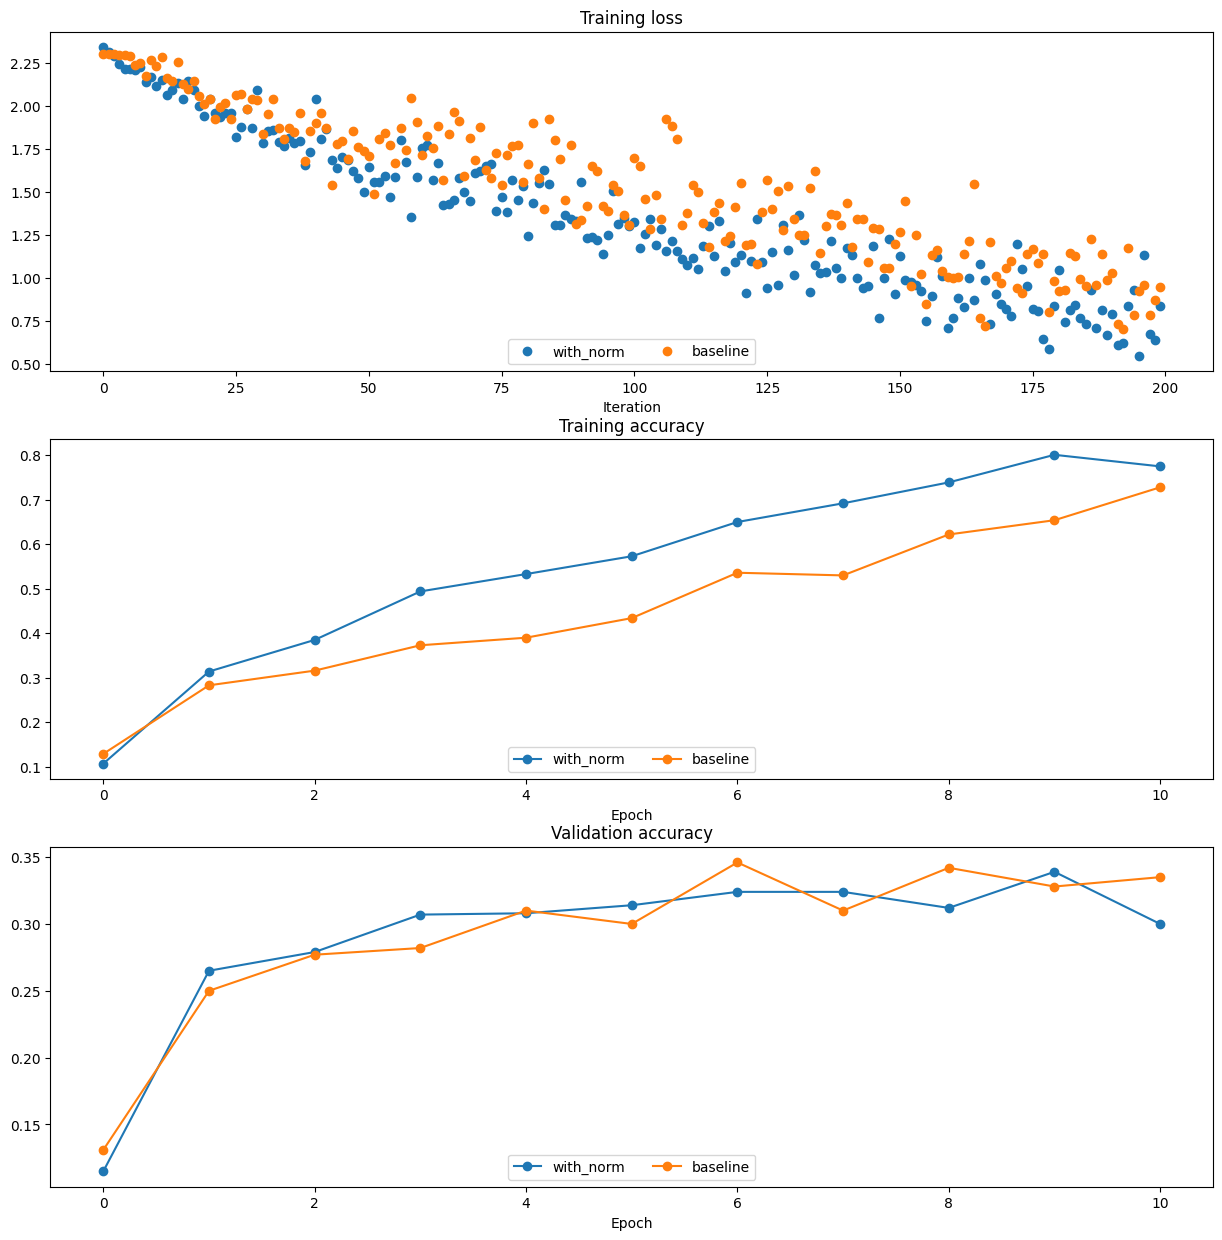

In [16]:
def plot_training_history(title, label, baseline, bn_solvers, plot_fn, bl_marker='.', bn_marker='.', labels=None):
    """utility function for plotting training history

    中文对照：
    绘制训练历史的辅助函数。
    """
    plt.title(title)
    plt.xlabel(label)
    bn_plots = [plot_fn(bn_solver) for bn_solver in bn_solvers]
    bl_plot = plot_fn(baseline)
    num_bn = len(bn_plots)
    for i in range(num_bn):
        label='with_norm'
        if labels is not None:
            label += str(labels[i])
        plt.plot(bn_plots[i], bn_marker, label=label)
    label='baseline'
    if labels is not None:
        label += str(labels[0])
    plt.plot(bl_plot, bl_marker, label=label)
    plt.legend(loc='lower center', ncol=num_bn+1)


plt.subplot(3, 1, 1)
plot_training_history('Training loss','Iteration', solver, [bn_solver], \
                      lambda x: x.loss_history, bl_marker='o', bn_marker='o')
plt.subplot(3, 1, 2)
plot_training_history('Training accuracy','Epoch', solver, [bn_solver], \
                      lambda x: x.train_acc_history, bl_marker='-o', bn_marker='-o')
plt.subplot(3, 1, 3)
plot_training_history('Validation accuracy','Epoch', solver, [bn_solver], \
                      lambda x: x.val_acc_history, bl_marker='-o', bn_marker='-o')

plt.gcf().set_size_inches(15, 15)
plt.show()

# Batch Normalization and Initialization
We will now run a small experiment to study the interaction of batch normalization and weight initialization.

The first cell will train eight-layer networks both with and without batch normalization using different scales for weight initialization. The second layer will plot training accuracy, validation set accuracy, and training loss as a function of the weight initialization scale.

---

**中文对照（参考译文，不含解答）**

# 批次归一化和初始化
我们现在将进行一个小型试验,研究批量归一化和权重初始化的相互作用。

第一个单元将使用不同的权重初始化尺度,对八层网络进行训练,无论是否进行批量归一化。 第二个单元将绘制训练准确性、验证集的准确性以及训练损失,作为权重初始化规模的函数。

In [17]:
np.random.seed(231)

# Try training a very deep net with batchnorm.
# [中文] 尝试使用批归一化训练较深的网络。
hidden_dims = [50, 50, 50, 50, 50, 50, 50]
num_train = 1000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

bn_solvers_ws = {}
solvers_ws = {}
weight_scales = np.logspace(-4, 0, num=20)
for i, weight_scale in enumerate(weight_scales):
    print('Running weight scale %d / %d' % (i + 1, len(weight_scales)))
    bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization='batchnorm')
    model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=None)

    bn_solver = Solver(bn_model, small_data,
                  num_epochs=10, batch_size=50,
                  update_rule='adam',
                  optim_config={
                    'learning_rate': 1e-3,
                  },
                  verbose=False, print_every=200)
    bn_solver.train()
    bn_solvers_ws[weight_scale] = bn_solver

    solver = Solver(model, small_data,
                  num_epochs=10, batch_size=50,
                  update_rule='adam',
                  optim_config={
                    'learning_rate': 1e-3,
                  },
                  verbose=False, print_every=200)
    solver.train()
    solvers_ws[weight_scale] = solver

Running weight scale 1 / 20
Running weight scale 2 / 20
Running weight scale 3 / 20
Running weight scale 4 / 20
Running weight scale 5 / 20
Running weight scale 6 / 20
Running weight scale 7 / 20
Running weight scale 8 / 20
Running weight scale 9 / 20
Running weight scale 10 / 20
Running weight scale 11 / 20
Running weight scale 12 / 20
Running weight scale 13 / 20
Running weight scale 14 / 20
Running weight scale 15 / 20
Running weight scale 16 / 20


D:\cs231n\assignment2\cs231n\layers.py:23: RuntimeWarning: divide by zero encountered in log
  中文对照：


Running weight scale 17 / 20
Running weight scale 18 / 20
Running weight scale 19 / 20
Running weight scale 20 / 20


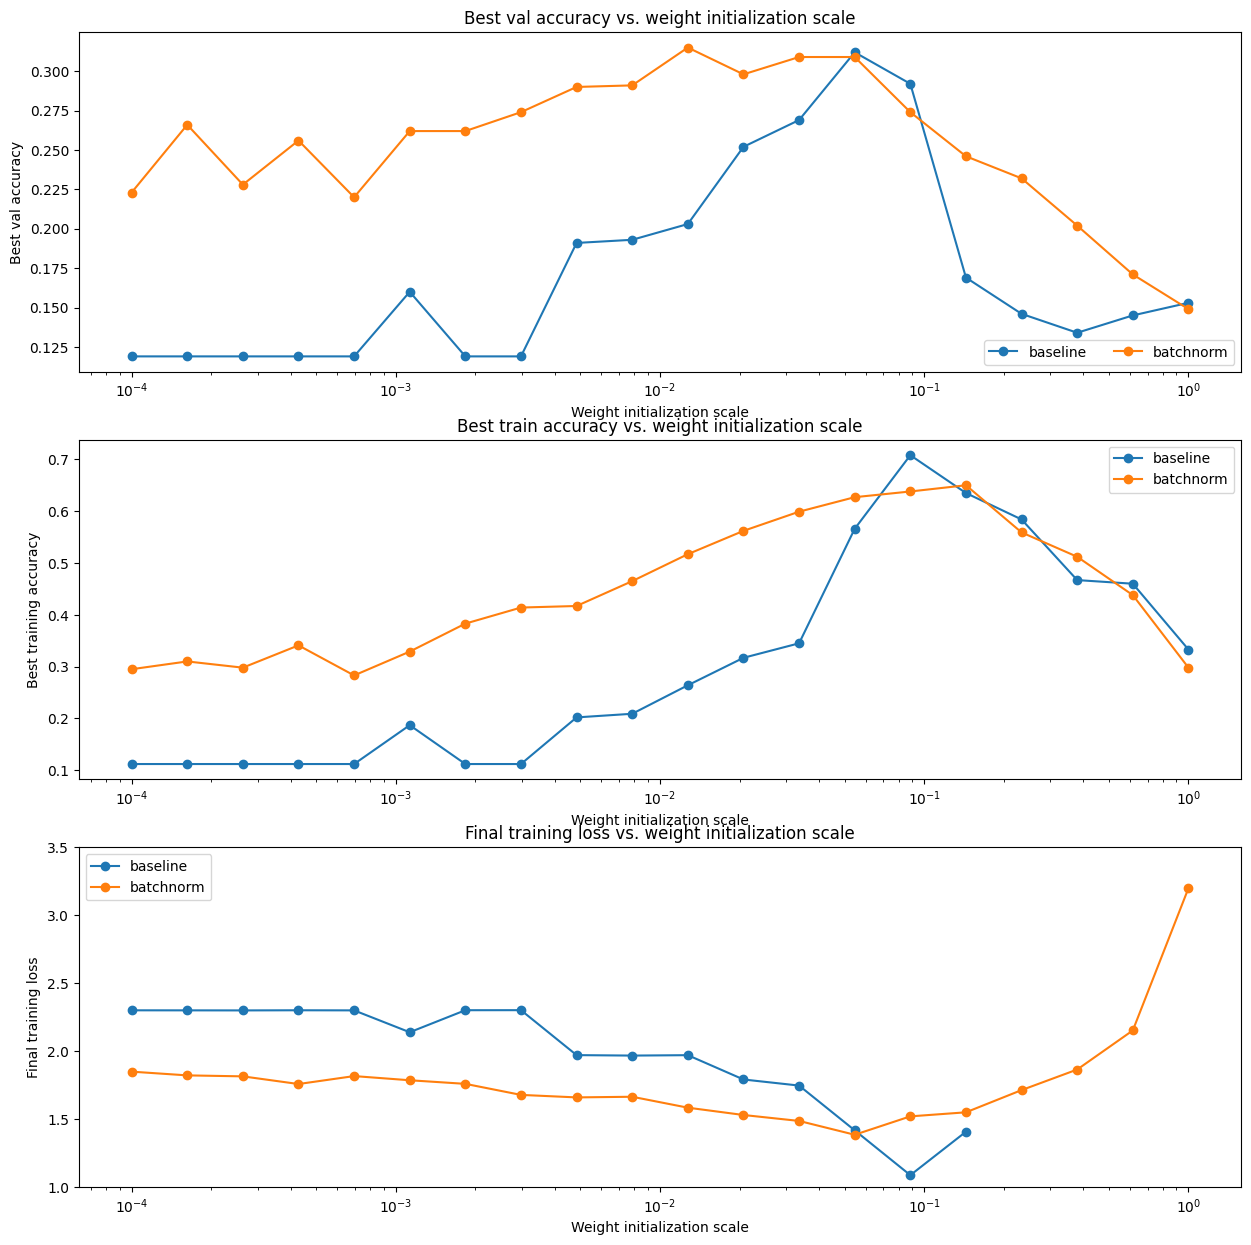

In [18]:
# Plot results of weight scale experiment.
# [中文] 绘制权重初始化尺度实验的结果。
best_train_accs, bn_best_train_accs = [], []
best_val_accs, bn_best_val_accs = [], []
final_train_loss, bn_final_train_loss = [], []

for ws in weight_scales:
  best_train_accs.append(max(solvers_ws[ws].train_acc_history))
  bn_best_train_accs.append(max(bn_solvers_ws[ws].train_acc_history))

  best_val_accs.append(max(solvers_ws[ws].val_acc_history))
  bn_best_val_accs.append(max(bn_solvers_ws[ws].val_acc_history))

  final_train_loss.append(np.mean(solvers_ws[ws].loss_history[-100:]))
  bn_final_train_loss.append(np.mean(bn_solvers_ws[ws].loss_history[-100:]))

plt.subplot(3, 1, 1)
plt.title('Best val accuracy vs. weight initialization scale')
plt.xlabel('Weight initialization scale')
plt.ylabel('Best val accuracy')
plt.semilogx(weight_scales, best_val_accs, '-o', label='baseline')
plt.semilogx(weight_scales, bn_best_val_accs, '-o', label='batchnorm')
plt.legend(ncol=2, loc='lower right')

plt.subplot(3, 1, 2)
plt.title('Best train accuracy vs. weight initialization scale')
plt.xlabel('Weight initialization scale')
plt.ylabel('Best training accuracy')
plt.semilogx(weight_scales, best_train_accs, '-o', label='baseline')
plt.semilogx(weight_scales, bn_best_train_accs, '-o', label='batchnorm')
plt.legend()

plt.subplot(3, 1, 3)
plt.title('Final training loss vs. weight initialization scale')
plt.xlabel('Weight initialization scale')
plt.ylabel('Final training loss')
plt.semilogx(weight_scales, final_train_loss, '-o', label='baseline')
plt.semilogx(weight_scales, bn_final_train_loss, '-o', label='batchnorm')
plt.legend()
plt.gca().set_ylim(1.0, 3.5)

plt.gcf().set_size_inches(15, 15)
plt.show()

## Inline Question 1:
Describe the results of this experiment. How does the weight initialization scale affect models with/without batch normalization differently, and why?

## Answer:
[FILL THIS IN]


---

**中文对照（参考译文，不含解答）**

## 随堂问题 1

描述本次实验的结果。权重初始化尺度对使用批归一化和不使用批归一化的模型分别有什么影响？为什么？

**你的回答：** 使用批归一化的准确率明显要比不使用批归一化的模型高许多，且权重初始化尺度变化时，使用批归一化的模型表现更稳定。这是因为批归一化减轻了初始化尺度对网络中间隐藏层的数值分布影响，有助于训练。（因为权重尺度改变时，隐藏层输出的尺度通常也会改变；批归一化会减去当前批次的均值并除以标准差，抵消大部分尺度变化，使传给后续层的数值更加稳定，因此模型通常对权重初始化尺度不那么敏感。）

# Batch Normalization and Batch Size
We will now run a small experiment to study the interaction of batch normalization and batch size.

The first cell will train 6-layer networks both with and without batch normalization using different batch sizes. The second layer will plot training accuracy and validation set accuracy over time.

---

**中文对照（参考译文，不含解答）**

# 批次归一化和批次大小
我们现在将进行一个小型试验,研究批量归一化和批量大小之间的相互作用。

第一个单元将使用不同的批量大小来训练 6 - 层网络,无论是否进行批量归一化。 第二层将绘制训练的准确性和验证设置的准确性。

In [19]:
def run_batchsize_experiments(normalization_mode):
    np.random.seed(231)

    # Try training a very deep net with batchnorm.
    # [中文] 尝试使用批归一化训练较深的网络。
    hidden_dims = [100, 100, 100, 100, 100]
    num_train = 1000
    small_data = {
      'X_train': data['X_train'][:num_train],
      'y_train': data['y_train'][:num_train],
      'X_val': data['X_val'],
      'y_val': data['y_val'],
    }
    n_epochs=10
    weight_scale = 2e-2
    batch_sizes = [5,10,50]
    lr = 10**(-3.5)
    solver_bsize = batch_sizes[0]

    print('No normalization: batch size = ',solver_bsize)
    model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=None)
    solver = Solver(model, small_data,
                    num_epochs=n_epochs, batch_size=solver_bsize,
                    update_rule='adam',
                    optim_config={
                      'learning_rate': lr,
                    },
                    verbose=False)
    solver.train()

    bn_solvers = []
    for i in range(len(batch_sizes)):
        b_size=batch_sizes[i]
        print('Normalization: batch size = ',b_size)
        bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=normalization_mode)
        bn_solver = Solver(bn_model, small_data,
                        num_epochs=n_epochs, batch_size=b_size,
                        update_rule='adam',
                        optim_config={
                          'learning_rate': lr,
                        },
                        verbose=False)
        bn_solver.train()
        bn_solvers.append(bn_solver)

    return bn_solvers, solver, batch_sizes

batch_sizes = [5,10,50]
bn_solvers_bsize, solver_bsize, batch_sizes = run_batchsize_experiments('batchnorm')

No normalization: batch size =  5
Normalization: batch size =  5
Normalization: batch size =  10
Normalization: batch size =  50


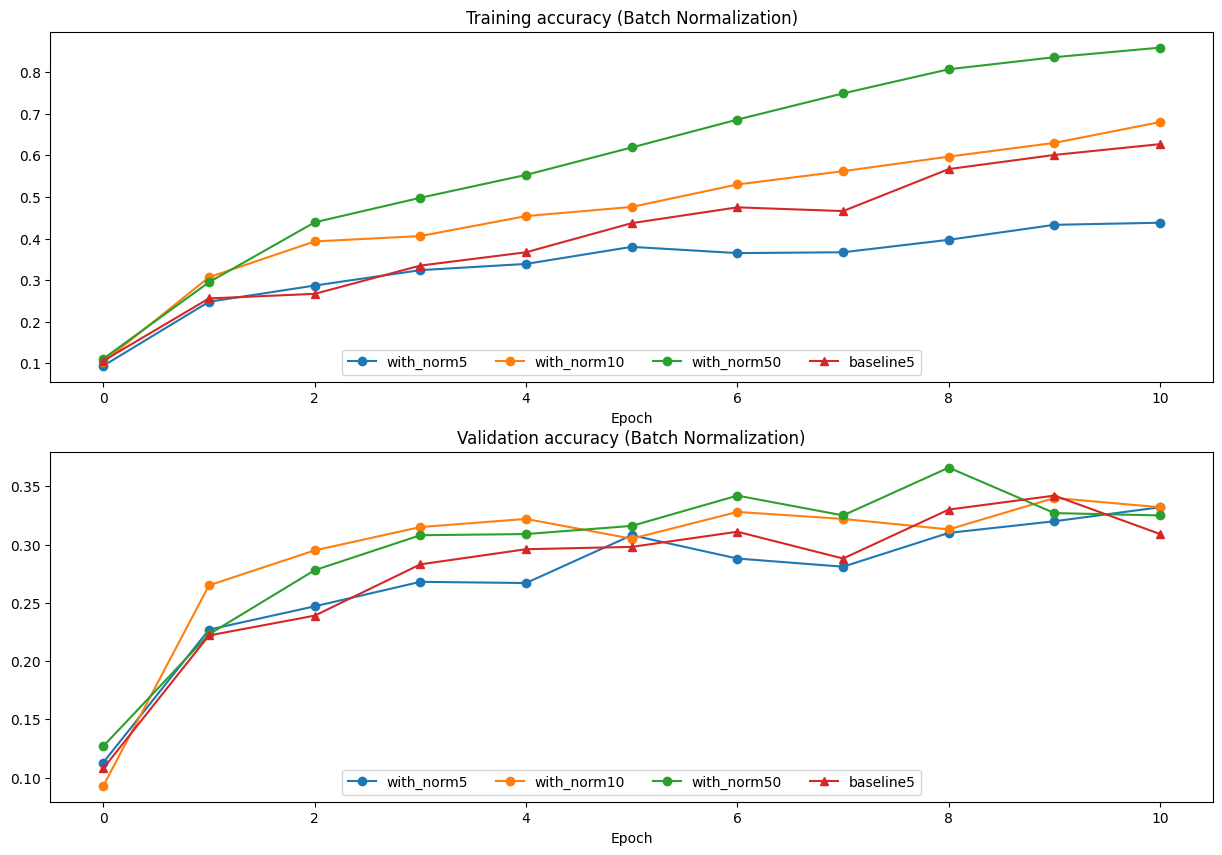

In [20]:
plt.subplot(2, 1, 1)
plot_training_history('Training accuracy (Batch Normalization)','Epoch', solver_bsize, bn_solvers_bsize, \
                      lambda x: x.train_acc_history, bl_marker='-^', bn_marker='-o', labels=batch_sizes)
plt.subplot(2, 1, 2)
plot_training_history('Validation accuracy (Batch Normalization)','Epoch', solver_bsize, bn_solvers_bsize, \
                      lambda x: x.val_acc_history, bl_marker='-^', bn_marker='-o', labels=batch_sizes)

plt.gcf().set_size_inches(15, 10)
plt.show()

## Inline Question 2:
Describe the results of this experiment. What does this imply about the relationship between batch normalization and batch size? Why is this relationship observed?

## Answer:
[FILL THIS IN]


---

**中文对照（参考译文，不含解答）**

## 随堂问题 2

描述本次实验的结果。这说明批归一化与批大小之间存在怎样的关系？为什么会观察到这种关系？

**你的回答：** 批大小越大，批归一化训练出来的模型在训练集上的准确率越高。因为样本数量越多，模型学到的训练集特征就越多。（批归一化使用当前批次的样本计算均值和方差；批次较大时，统计量通常更加稳定，有助于模型训练。）

# Layer Normalization
Batch normalization has proved to be effective in making networks easier to train, but the dependency on batch size makes it less useful in complex networks which have a cap on the input batch size due to hardware limitations.

Several alternatives to batch normalization have been proposed to mitigate this problem; one such technique is Layer Normalization [2]. Instead of normalizing over the batch, we normalize over the features. In other words, when using Layer Normalization, each feature vector corresponding to a single datapoint is normalized based on the sum of all terms within that feature vector.

[2] [Ba, Jimmy Lei, Jamie Ryan Kiros, and Geoffrey E. Hinton. "Layer Normalization." stat 1050 (2016): 21.](https://arxiv.org/pdf/1607.06450.pdf)

---

**中文对照（参考译文，不含解答）**

# 层归一化
批量归一化在使网络更容易训练方面已证明是有效的,但由于对批量规模的依赖,在由于硬件限制而限制输入批量规模的复杂网络中,批量的用处较小。

为缓解这一问题,提出了分批归一化的几种替代办法;其中一种办法是层归一化[2)没有在批量中实现归一化,而是在特性上实现归一化。换句话说,在使用层归一化时,每个与单一数据点相对应的特征向量根据该特性矢值内所有条件的总和而实现归一化。

[ 2 ]  [Ba, Jimmy Lei, Jamie Ryan Kiros, and Geoffrey E. Hinton. "Layer Normalization." stat 1050 (2016): 21.](https://arxiv.org/pdf/1607.06450.pdf)

## Inline Question 3:
Which of these data preprocessing steps is analogous to batch normalization, and which is analogous to layer normalization?

1. Scaling each image in the dataset, so that the RGB channels for each row of pixels within an image sums up to 1.
2. Scaling each image in the dataset, so that the RGB channels for all pixels within an image sums up to 1.  
3. Subtracting the mean image of the dataset from each image in the dataset.
4. Setting all RGB values to either 0 or 1 depending on a given threshold.

## Answer:
[FILL THIS IN]


---

**中文对照（参考译文，不含解答）**

## 随堂问题 3

以下数据预处理步骤中，哪些与批归一化类似，哪些与层归一化类似？

1. 缩放数据集中的每张图像，使图像中每一行像素的所有 RGB 通道数值之和为 1。
2. 缩放数据集中的每张图像，使整张图像所有像素的所有 RGB 通道数值之和为 1。
3. 从数据集的每张图像中减去数据集的平均图像。
4. 根据给定阈值，将所有 RGB 数值设置为 0 或 1。

**你的回答：** 1、层归一化；2、层归一化；3、批归一化；4、都不类似

批归一化：跨样本，按特征计算；层归一化：单个样本内部，按特征计算

# Layer Normalization: Implementation

Now you'll implement layer normalization. This step should be relatively straightforward, as conceptually the implementation is almost identical to that of batch normalization. One significant difference though is that for layer normalization, we do not keep track of the moving moments, and the testing phase is identical to the training phase, where the mean and variance are directly calculated per datapoint.

Here's what you need to do:

* In `cs231n/layers.py`, implement the forward pass for layer normalization in the function `layernorm_forward`.

Run the cell below to check your results.
* In `cs231n/layers.py`, implement the backward pass for layer normalization in the function `layernorm_backward`.

Run the second cell below to check your results.
* Modify `cs231n/classifiers/fc_net.py` to add layer normalization to the `FullyConnectedNet`. When the `normalization` flag is set to `"layernorm"` in the constructor, you should insert a layer normalization layer before each ReLU nonlinearity.

Run the third cell below to run the batch size experiment on layer normalization.

---

**中文对照（参考译文，不含解答）**

# 图层归一化:实施

现在,你将实施层的归一化。这个步骤应该相对简单,因为从概念上讲,实施与批量归一化几乎完全相同。但一个显著的区别是,对于层的归一化,我们并不跟踪移动时刻,测试阶段与训练阶段完全相同,而训练阶段的平均值和差异是按数据点直接计算的。

这就是你需要做的:

* 在 `cs231n/layers.py` 中,在函数 `layernorm_forward` 中执行层归一化的 前向传播。

运行下面的单元格检查您的检查结果。
* 在 `cs231n/layers.py` 中,在函数 `layernorm_backward` 中执行层归一化的 反向传播。

运行下面第二个单元格检查您的检查结果。
* 修改`cs231n/classifiers/fc_net.py`以在`FullyConnectedNet`。当`normalization`标记设置为`"layernorm"`在构造函数中,您应该在每个 ReLU 的非直线性之前插入一个层归一化层。

运行下面第三个单元格, 运行分批大小实验。

In [21]:
# Check the training-time forward pass by checking means and variances
# of features both before and after layer normalization.
# [中文] 比较层归一化前后的特征均值与方差，检查训练模式下的前向传播。

# Simulate the forward pass for a two-layer network.
# [中文] 模拟双层网络的前向传播。
np.random.seed(231)
N, D1, D2, D3 =4, 50, 60, 3
X = np.random.randn(N, D1)
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)
a = np.maximum(0, X.dot(W1)).dot(W2)

print('Before layer normalization:')
print_mean_std(a,axis=1)

gamma = np.ones(D3)
beta = np.zeros(D3)

# Means should be close to zero and stds close to one.
# [中文] 均值应接近 0，标准差应接近 1。
print('After layer normalization (gamma=1, beta=0)')
a_norm, _ = layernorm_forward(a, gamma, beta, {'mode': 'train'})
print_mean_std(a_norm,axis=1)

gamma = np.asarray([3.0,3.0,3.0])
beta = np.asarray([5.0,5.0,5.0])

# Now means should be close to beta and stds close to gamma.
# [中文] 此时均值应接近 beta，标准差应接近 gamma。
print('After layer normalization (gamma=', gamma, ', beta=', beta, ')')
a_norm, _ = layernorm_forward(a, gamma, beta, {'mode': 'train'})
print_mean_std(a_norm,axis=1)

Before layer normalization:
  means: [-59.06673243 -47.60782686 -43.31137368 -26.40991744]
  stds:  [10.07429373 28.39478981 35.28360729  4.01831507]

After layer normalization (gamma=1, beta=0)
  means: [ 2.59052039e-16  0.00000000e+00  2.22044605e-16 -5.55111512e-16]
  stds:  [0.99999995 0.99999999 1.         0.99999969]

After layer normalization (gamma= [3. 3. 3.] , beta= [5. 5. 5.] )
  means: [5. 5. 5. 5.]
  stds:  [2.99999985 2.99999998 2.99999999 2.99999907]



In [22]:
# Gradient check batchnorm backward pass.
# [中文] 对批归一化的反向传播做数值梯度检查。
np.random.seed(231)
N, D = 4, 5
x = 5 * np.random.randn(N, D) + 12
gamma = np.random.randn(D)
beta = np.random.randn(D)
dout = np.random.randn(N, D)

ln_param = {}
fx = lambda x: layernorm_forward(x, gamma, beta, ln_param)[0]
fg = lambda a: layernorm_forward(x, a, beta, ln_param)[0]
fb = lambda b: layernorm_forward(x, gamma, b, ln_param)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
da_num = eval_numerical_gradient_array(fg, gamma.copy(), dout)
db_num = eval_numerical_gradient_array(fb, beta.copy(), dout)

_, cache = layernorm_forward(x, gamma, beta, ln_param)
dx, dgamma, dbeta = layernorm_backward(dout, cache)

# You should expect to see relative errors between 1e-12 and 1e-8.
# [中文] 相对误差应在 1e-12～1e-8 量级。
print('dx error: ', rel_error(dx_num, dx))
print('dgamma error: ', rel_error(da_num, dgamma))
print('dbeta error: ', rel_error(db_num, dbeta))

dx error:  1.433615657860454e-09
dgamma error:  4.519489546032799e-12
dbeta error:  2.276445013433725e-12


# Layer Normalization and Batch Size

We will now run the previous batch size experiment with layer normalization instead of batch normalization. Compared to the previous experiment, you should see a markedly smaller influence of batch size on the training history!

---

**中文对照（参考译文，不含解答）**

# 图层归一化和批量大小

我们现在将进行先前的批量规模实验, 使用分层归一化, 而不是批量归一化。 与前一次实验相比, 您应该看到批量大小对训练历史的影响明显较小 !

No normalization: batch size =  5
Normalization: batch size =  5
Normalization: batch size =  10
Normalization: batch size =  50


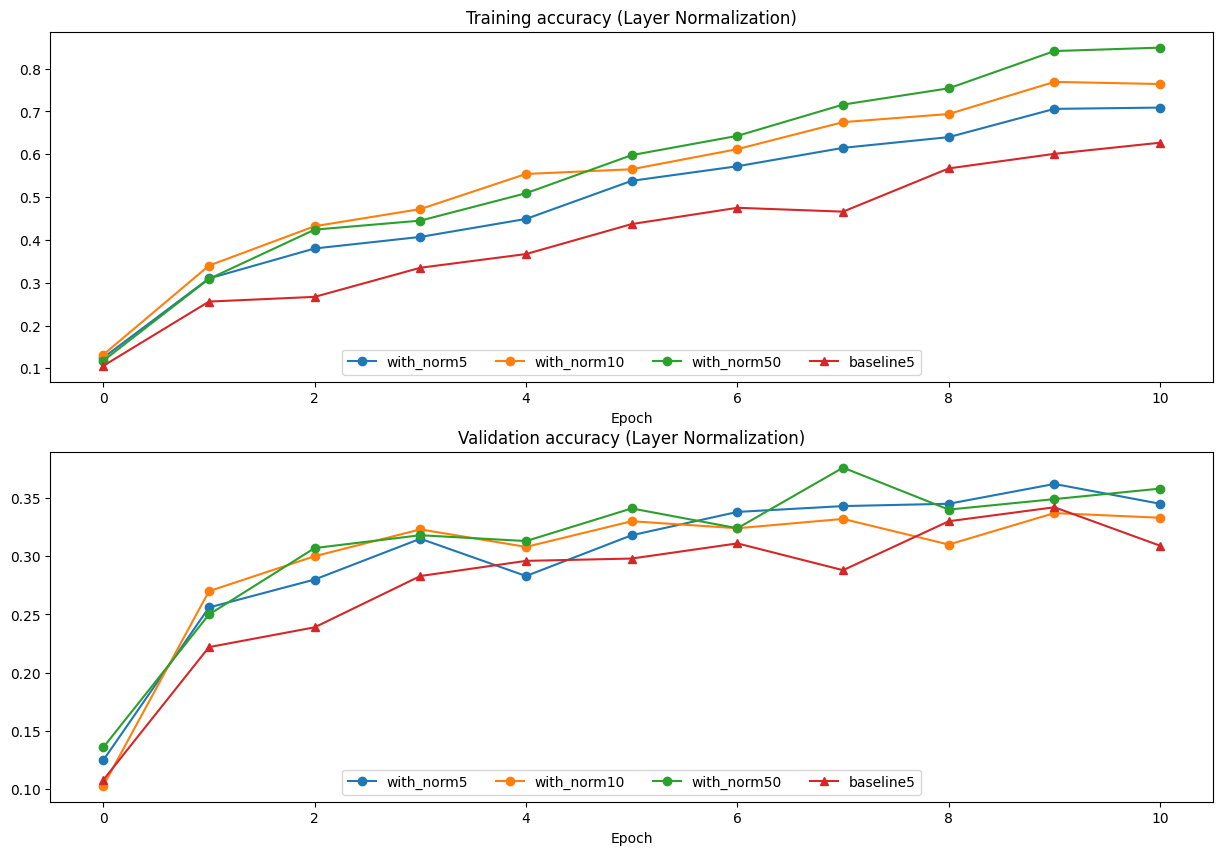

In [28]:
ln_solvers_bsize, solver_bsize, batch_sizes = run_batchsize_experiments('layernorm')

plt.subplot(2, 1, 1)
plot_training_history('Training accuracy (Layer Normalization)','Epoch', solver_bsize, ln_solvers_bsize, \
                      lambda x: x.train_acc_history, bl_marker='-^', bn_marker='-o', labels=batch_sizes)
plt.subplot(2, 1, 2)
plot_training_history('Validation accuracy (Layer Normalization)','Epoch', solver_bsize, ln_solvers_bsize, \
                      lambda x: x.val_acc_history, bl_marker='-^', bn_marker='-o', labels=batch_sizes)

plt.gcf().set_size_inches(15, 10)
plt.show()

## Inline Question 4:
When is layer normalization likely to not work well, and why?

1. Using it in a very deep network
2. Having a very small dimension of features
3. Having a high regularization term


## Answer:
[FILL THIS IN]


---

**中文对照（参考译文，不含解答）**

## 随堂问题 4

在哪些情况下，层归一化可能效果不佳？为什么？

1. 用于非常深的网络。
2. 特征维度非常小。
3. 正则化项较大。

**你的回答：** 2、层归一化本就会去除或压制样本的一些信息，当特征维度很小的时候，层归一化导致样本本就不多的特征信息更少，是不同输入变得难以区分。拿极端例子来说，若只有一个特征，那么层归一化之后恒为0，无法映射原始输入。